In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import numpy as np
from tqdm import tqdm
import pandas as pd
import copy
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
device

device(type='cuda')

In [ ]:
def save_checkpoint(model, optimizer, epoch, filename="checkpoint.pth"):
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict()
    }
    torch.save(checkpoint, filename)
    print(f"Checkpoint saved to {filename}")

def load_checkpoint(model, optimizer, filename="checkpoint.pth"):
    checkpoint = torch.load(filename)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    epoch = checkpoint['epoch']
    print(f"Checkpoint loaded from {filename}, starting from epoch {epoch}")
    return epoch

# Модель - WRN

In [ ]:
# -------------------------------
# WideResNet
# -------------------------------

# на основе https://github.com/bmsookim/wide-resnet.pytorch/

class BasicBlock(nn.Module):
    def __init__(self, in_planes, out_planes, stride, dropout_rate=0.0):
        super(BasicBlock, self).__init__()
        self.bn1 = nn.BatchNorm2d(in_planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv1 = nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                               padding=1, bias=False)
        self.dropout = nn.Dropout(p=dropout_rate)
        self.bn2 = nn.BatchNorm2d(out_planes)
        self.conv2 = nn.Conv2d(out_planes, out_planes, kernel_size=3, stride=1,
                               padding=1, bias=False)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != out_planes:
            self.shortcut = nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)

    def forward(self, x):
        out = self.bn1(x)
        out = self.relu(out)
        out = self.conv1(out)
        out = self.dropout(out)
        out = self.bn2(out)
        out = self.relu(out)
        out = self.conv2(out)
        out += self.shortcut(x)
        return out


class NetworkBlock(nn.Module):
    def __init__(self, num_layers, in_planes, out_planes, block, stride, dropout_rate):
        super(NetworkBlock, self).__init__()
        layers = []
        for i in range(num_layers):
            s = stride if i == 0 else 1
            layers.append(block(in_planes if i == 0 else out_planes, out_planes, s, dropout_rate))
        self.layer = nn.Sequential(*layers)

    def forward(self, x):
        return self.layer(x)


class WideResNet(nn.Module):
    def __init__(self, depth=28, widen_factor=2, num_classes=10, dropout_rate=0.0):
        super(WideResNet, self).__init__()
        # проверим корректность глубины сети (должна быть 6n+4)
        assert (depth - 4) % 6 == 0
        n = (depth - 4) // 6 # колво блоков в каждой группе
        k = widen_factor
        nStages = [16, 16 * k, 32 * k, 64 * k] # колво каналов на каждом этапе

        self.conv1 = nn.Conv2d(3, nStages[0], kernel_size=3, stride=1, padding=1, bias=False)
        self.block1 = NetworkBlock(n, nStages[0], nStages[1], BasicBlock, 1, dropout_rate)
        self.block2 = NetworkBlock(n, nStages[1], nStages[2], BasicBlock, 2, dropout_rate)
        self.block3 = NetworkBlock(n, nStages[2], nStages[3], BasicBlock, 2, dropout_rate)

        # Финальные слои
        self.bn1 = nn.BatchNorm2d(nStages[3])
        self.relu = nn.ReLU(inplace=True)
        self.fc = nn.Linear(nStages[3], num_classes)

        self._initialize_weights()

    def forward(self, x):
        out = self.conv1(x)
        out = self.block1(out)
        out = self.block2(out) #тут уменьшили размерность
        out = self.block3(out) #тут уменьшили размерность
        out = self.bn1(out)
        out = self.relu(out)
        out = F.adaptive_avg_pool2d(out, 1) # глобальное усреднение
        out = out.view(out.size(0), -1)   # развернули в вектор
        return self.fc(out)

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1) # задаем веса batchnorm как 1
                nn.init.constant_(m.bias, 0)   # смещения bn как 0
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight)
                nn.init.constant_(m.bias, 0)


# грузим cifar10

In [ ]:

# аугментация и предобработка
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),    #https://pytorch.org/vision/main/generated/torchvision.transforms.RandomHorizontalFlip.html
    transforms.RandomCrop(32, padding=4), #https://pytorch.org/vision/main/generated/torchvision.transforms.RandomCrop.html
    transforms.ToTensor(),                # (нормализация в [0, 1]) https://pytorch.org/vision/main/generated/torchvision.transforms.ToTensor.html
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)) # нормализация по каналам
])

# датасет
trainset = torchvision.datasets.CIFAR10(root='./data_CIFAR10', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data_CIFAR10', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=100, shuffle=False, num_workers=2)

# модель, критерий, оптимизатор
model = WideResNet(depth=28, widen_factor=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 120, 160], gamma=0.2)

100%|██████████| 170M/170M [00:12<00:00, 13.1MB/s]


In [ ]:
class Trainer:
    def __init__(self, model, trainloader, testloader, criterion, optimizer, scheduler=None):
        self.model = model
        self.trainloader = trainloader
        self.testloader = testloader
        self.criterion = criterion
        self.optimizer = optimizer
        self.scheduler = scheduler

        self.train_losses = []
        self.test_losses = []
        self.train_accs = []
        self.test_accs = []

    def train(self, epoch):
        self.model.train()
        correct, total, running_loss = 0, 0, 0
        for inputs, targets in self.trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            loss = self.criterion(outputs, targets)
            loss.backward()
            self.optimizer.step()

            # сбор статистики
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        acc = 100. * correct / total
        self.train_losses.append(running_loss / len(self.trainloader))
        self.train_accs.append(acc)
        print(f"[{epoch}] Train Loss: {self.train_losses[-1]:.3f} | Acc: {acc:.2f}%")

    def test(self):
        self.model.eval()
        correct, total, running_loss = 0, 0, 0
        with torch.no_grad():
            for inputs, targets in self.testloader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, targets)
                running_loss += loss.item()
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

        acc = 100. * correct / total
        self.test_losses.append(running_loss / len(self.testloader))
        self.test_accs.append(acc)
        print(f"     Test Loss: {self.test_losses[-1]:.3f} | Acc: {acc:.2f}%")

    # сохраняется текущее состаяние оптимизатора и модели
    def save_checkpoint(self, epoch, filename="checkpoint.pth"):
        save_checkpoint(self.model, self.optimizer, epoch, filename)
    # загружаем их же
    def load_checkpoint(self, filename="checkpoint.pth"):
        epoch = load_checkpoint(self.model, self.optimizer, filename)
        return epoch

    def plot_metrics(self):
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(self.train_losses, label='Train Loss')
        plt.plot(self.test_losses, label='Test Loss')
        plt.title('Loss')
        plt.xlabel('Epoch')
        plt.grid()
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(self.train_accs, label='Train Acc')
        plt.plot(self.test_accs, label='Test Acc')
        plt.title('Accuracy')
        plt.xlabel('Epoch')
        plt.grid()
        plt.legend()

        plt.tight_layout()
        plt.show()


# IMP WITH TICKET

In [ ]:
class IMPTrainer:
    def __init__(self, model, trainer, pruning_ratio=0.2):
        self.model = model
        self.trainer = trainer
        self.pruning_ratio = pruning_ratio

        self.initial_state = self._get_weights()  # изначальные веса
        self.matching_ticket = None               # будет установлен после T0
        self.masks = self._initialize_masks()

    def _get_weights(self):
        return {k: v.clone().detach() for k, v in self.model.state_dict().items()}

    def _initialize_masks(self):
        return {
            name: torch.ones_like(param, dtype=torch.bool)
            for name, param in self.model.named_parameters()
            if "weight" in name
        }

    def _apply_mask(self):
        with torch.no_grad():
            for name, param in self.model.named_parameters():
                if name in self.masks:
                    param.data *= self.masks[name]

    def _prune(self):
        for name, param in self.model.named_parameters():
            if name in self.masks:
                current_weights = param.data[self.masks[name]]
                k = int(current_weights.numel() * self.pruning_ratio)
                if k == 0:
                    continue
                threshold = current_weights.abs().kthvalue(k).values
                new_mask = (param.data.abs() > threshold) & self.masks[name]
                self.masks[name] = new_mask

    def _reset_to_ticket(self):
        self.model.load_state_dict(self.matching_ticket)
        self._apply_mask()

    def _log_sparsity(self, iteration):
        total_params, zero_params = 0, 0
        for name, param in self.model.named_parameters():
            if name in self.masks:
                mask = self.masks[name]
                total_params += mask.numel()
                zero_params += (~mask).sum().item()
        sparsity = 100 * zero_params / total_params
        print(f"[IMP Iteration {iteration}] Sparsity: {sparsity:.2f}% ({total_params - zero_params} / {total_params} non-zero)")

    def run(self, C=5, T=20, T0=5):
        print(f"\n[IMP] Step 1: Getting matching ticket (T0={T0})...")
        self.model.load_state_dict(self.initial_state)
        for epoch in range(1, T0 + 1):
            self.trainer.train(epoch)
            self.trainer.test()
            self.trainer.scheduler.step()

        self.matching_ticket = self._get_weights()

        for c in range(1, C + 1):
            print(f"\n[IMP Iteration {c}/{C}]")
            self._reset_to_ticket()
            for epoch in range(1, T + 1):
                self.trainer.train(epoch)
                self.trainer.test()
                self.trainer.scheduler.step()

            self._prune()
            self._log_sparsity(c)


In [ ]:
wrn28_2_imp_model = WideResNet(depth=28, widen_factor=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(wrn28_2_imp_model.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 120, 160], gamma=0.2)

imp_trainer = Trainer(wrn28_2_imp_model, trainloader, testloader, criterion, optimizer, scheduler)

wrn28_2_model_imp_trainer = IMPTrainer(wrn28_2_imp_model, imp_trainer, pruning_ratio=0.2)

# С итераций по T эпох
wrn28_2_model_imp_trainer.run(C=10, T=20, T0=20)


[IMP] Step 1: Getting matching ticket (T0=20)...
[1] Train Loss: 1.544 | Acc: 42.73%
     Test Loss: 1.355 | Acc: 51.67%
[2] Train Loss: 1.062 | Acc: 61.72%
     Test Loss: 1.223 | Acc: 57.63%
[3] Train Loss: 0.883 | Acc: 68.44%
     Test Loss: 0.955 | Acc: 65.58%
[4] Train Loss: 0.759 | Acc: 73.05%
     Test Loss: 0.810 | Acc: 72.00%
[5] Train Loss: 0.657 | Acc: 77.15%
     Test Loss: 0.810 | Acc: 71.79%
[6] Train Loss: 0.589 | Acc: 79.68%
     Test Loss: 0.734 | Acc: 74.47%
[7] Train Loss: 0.531 | Acc: 81.71%
     Test Loss: 0.586 | Acc: 79.57%
[8] Train Loss: 0.495 | Acc: 82.73%
     Test Loss: 0.592 | Acc: 79.28%
[9] Train Loss: 0.456 | Acc: 84.27%
     Test Loss: 0.496 | Acc: 83.38%
[10] Train Loss: 0.429 | Acc: 85.12%
     Test Loss: 0.611 | Acc: 79.29%
[11] Train Loss: 0.409 | Acc: 85.88%
     Test Loss: 0.494 | Acc: 83.08%
[12] Train Loss: 0.383 | Acc: 86.78%
     Test Loss: 0.499 | Acc: 82.65%
[13] Train Loss: 0.366 | Acc: 87.27%
     Test Loss: 0.487 | Acc: 83.42%
[14] Train

In [ ]:

pd.concat([
    pd.DataFrame(imp_trainer.test_losses).rename(columns = {0:'imp_test_losses'}),
    pd.DataFrame(imp_trainer.train_losses).rename(columns = {0:'imp_train_losses'}),
    pd.DataFrame(imp_trainer.test_accs).rename(columns = {0:'imp_test_accs'}),
    pd.DataFrame(imp_trainer.train_accs).rename(columns = {0:'imp_train_accs'}),
], axis = 1).to_csv('imp_1_metrics.csv', index=False)

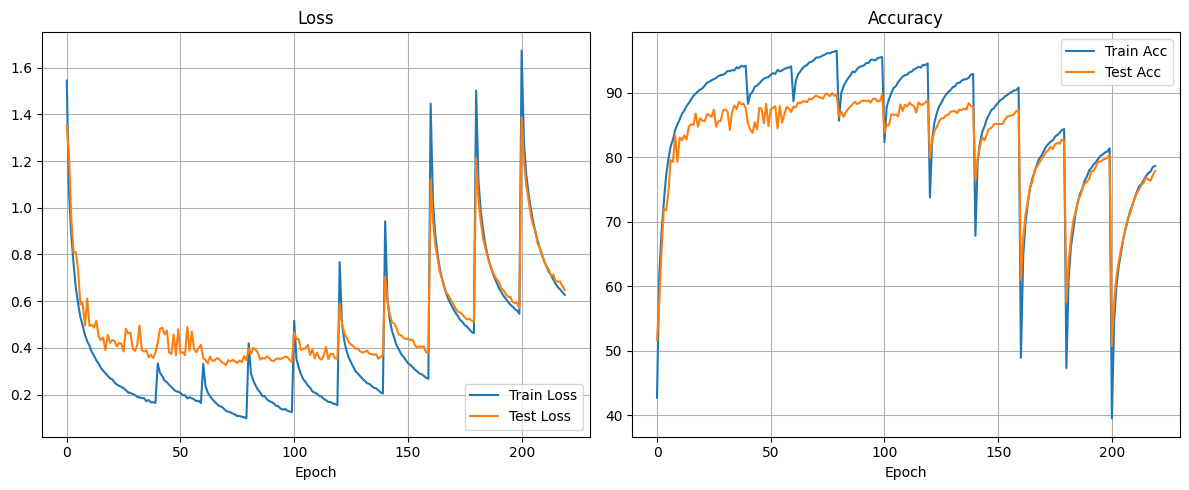

In [ ]:
imp_trainer.plot_metrics()

# Ансамбль IMP

In [ ]:
class IMPEnsembleTrainer:
    def __init__(self, model, trainloader, testloader,
                 pruning_ratio=0.2, n=3, device='cuda'):
        self.n = n       # количество моделей в ансамбле
        self.models = []
        self.trainers = []
        self.masks = []
        self.initial_states = []   # начальные веса каждой модели
        self.device = device
        self.pruning_ratio = pruning_ratio # доля прунинга
        self.history = []       # сохраняем логи по каждой итерации

        for i in range(n):
            model_i = copy.deepcopy(model).to(device)

            criterion = nn.CrossEntropyLoss()
            optimizer = torch.optim.SGD(model_i.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
            scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 120, 160], gamma=0.2)

            trainer_i = Trainer(model_i, trainloader, testloader, criterion, optimizer, scheduler)

            self.models.append(model_i)
            self.trainers.append(trainer_i)
            self.initial_states.append(self._get_weights(model_i))
            self.masks.append(self._initialize_masks(model_i))

    def _get_weights(self, model):
        # копия текущих весов
        return {k: v.clone().detach() for k, v in model.state_dict().items()}

    def _initialize_masks(self, model):
        return {
            name: torch.ones_like(param, dtype=torch.bool) # изначально все веса активные
            for name, param in model.named_parameters()
            if "weight" in name
        }

    def _apply_mask(self, model, mask):
        with torch.no_grad():
            for name, param in model.named_parameters():
                if name in mask:
                    param.data *= mask[name] # обнуляем отсеченные веса

    def _prune(self, model, mask):
        for name, param in model.named_parameters():
            if name in mask:
                current_weights = param.data[mask[name]]      # берем только активные веса
                k = int(current_weights.numel() * self.pruning_ratio) # число весов для удаления
                if k == 0:
                    continue # пропускаем если нечего удалять
                threshold = current_weights.abs().kthvalue(k).values
                new_mask = (param.data.abs() > threshold) & mask[name] # создаем новую маску - сохраняем только веса выше порога
                mask[name] = new_mask


    def _reset_weights(self, model, initial_state, mask):
        model.load_state_dict(initial_state) # восстанавливаем начальные веса
        self._apply_mask(model, mask) # пруним

    def _log_sparsity(self, mask, iteration, model_idx):
      # логи для одной модели
        total_params = 0
        zero_params = 0
        for m in mask.values():
            total_params += m.numel()
            zero_params += (~m).sum().item()
        sparsity = 100 * zero_params / total_params
        print(f"[Model {model_idx} | IMP Iteration {iteration}] Sparsity: {sparsity:.2f}% ({total_params - zero_params} / {total_params} non-zero)")

    def _log_iteration_metrics(self, iteration, testloader):
      # логи ансамбля после итерации
        # считаем sparsity и число параметров
        total_params_all = 0
        zero_params_all = 0

        for mask in self.masks:
            for m in mask.values():
                total_params_all += m.numel()
                zero_params_all += (~m).sum().item()

        mean_sparsity = 100 * zero_params_all / total_params_all
        total_nonzero_params = total_params_all - zero_params_all

        loss, acc = self.evaluate_ensemble(testloader, return_metrics=True)

        self.history.append({
            "iteration": iteration,
            "mean_sparsity_percent": mean_sparsity,
            "total_nonzero_params": total_nonzero_params,
            "ensemble_loss": loss,
            "ensemble_acc": acc
        })

        print(f"\n Iteration {iteration} | Mean Sparsity: {mean_sparsity:.2f}% "
              f"| Non-zero Params (total): {total_nonzero_params} "
              f"| Ensemble Loss: {loss:.4f} | Acc: {acc:.2f}%")

    def run(self, C=5, T=20):
        # для каждой модели из ансамбля
        for c in range(1, C + 1):
            print(f"\n=== [IMP Ensemble Iteration {c}/{C}] ===")

            for i in range(self.n):
                print(f"\n→ Model {i + 1}/{self.n}")
                model = self.models[i]
                mask = self.masks[i]
                initial_state = self.initial_states[i]

                self._reset_weights(model, initial_state, mask)
                for epoch in range(1, T + 1):
                    self.trainers[i].train(epoch)
                    self.trainers[i].test()
                    self.trainers[i].scheduler.step()
                self._prune(model, mask)

            self._log_iteration_metrics(c, self.trainers[0].testloader)


    def predict_ensemble(self, x):
      # усреднённые логиты от всех моделей ансамбля
        with torch.no_grad():
            logits = [model(x.to(self.device)) for model in self.models]  # предсказания всех моделе
            avg_logits = torch.stack(logits).mean(dim=0)
            return avg_logits

    def evaluate_ensemble(self, testloader, return_metrics=False):
        for model in self.models:
            model.eval()

        total = 0
        correct = 0
        total_loss = 0

        with torch.no_grad():
            for images, labels in testloader:
                images = images.to(self.device)
                labels = labels.to(self.device)
                outputs = self.predict_ensemble(images)
                loss = F.cross_entropy(outputs, labels)
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
                total_loss += loss.item() * labels.size(0)

        avg_loss = total_loss / total
        acc = 100. * correct / total

        if return_metrics:
            return avg_loss, acc
        else:
            print(f"Ensemble Test | Loss: {avg_loss:.4f} | Acc: {acc:.2f}%")


In [ ]:
ensemble = IMPEnsembleTrainer(
    model=WideResNet(depth=28, widen_factor=2),
    trainloader=trainloader,
    testloader=testloader,
    pruning_ratio=0.2,
    n=2,
    device=device
)

ensemble.run(C=10, T=10)




=== [IMP Ensemble Iteration 1/2] ===

→ Model 1/3
[1] Train Loss: 1.528 | Acc: 43.46%
     Test Loss: 1.302 | Acc: 52.14%
[2] Train Loss: 1.063 | Acc: 61.77%
     Test Loss: 1.254 | Acc: 56.37%

→ Model 2/3
[1] Train Loss: 1.510 | Acc: 44.20%
     Test Loss: 1.306 | Acc: 52.34%
[2] Train Loss: 1.050 | Acc: 62.19%
     Test Loss: 1.336 | Acc: 55.88%

→ Model 3/3
[1] Train Loss: 1.528 | Acc: 43.35%
     Test Loss: 1.401 | Acc: 48.08%
[2] Train Loss: 1.063 | Acc: 61.68%
     Test Loss: 1.674 | Acc: 47.77%

 Iteration 1 | Mean Sparsity: 20.00% | Non-zero Params (total): 3517980 | Ensemble Loss: 0.9935 | Acc: 64.61%

=== [IMP Ensemble Iteration 2/2] ===

→ Model 1/3
[1] Train Loss: 1.242 | Acc: 55.05%
     Test Loss: 1.224 | Acc: 57.59%
[2] Train Loss: 0.911 | Acc: 67.28%
     Test Loss: 1.053 | Acc: 63.44%

→ Model 2/3
[1] Train Loss: 1.242 | Acc: 55.06%
     Test Loss: 1.107 | Acc: 59.31%
[2] Train Loss: 0.903 | Acc: 67.59%
     Test Loss: 0.932 | Acc: 67.50%

→ Model 3/3
[1] Train Loss:

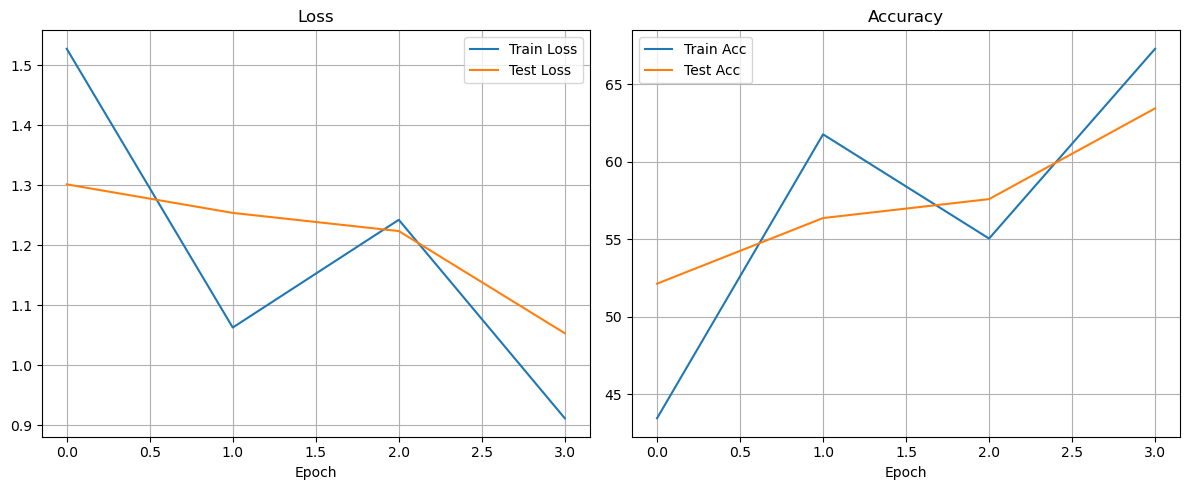

In [ ]:
ensemble.trainers[0].plot_metrics()

In [ ]:
ensemble.history

[{'iteration': 1,
  'mean_sparsity_percent': 19.9981989259049,
  'total_nonzero_params': 3517980,
  'ensemble_loss': 0.9934621119499206,
  'ensemble_acc': 64.61},
 {'iteration': 2,
  'mean_sparsity_percent': 35.99712646814828,
  'total_nonzero_params': 2814447,
  'ensemble_loss': 0.7870060396194458,
  'ensemble_acc': 72.24}]